# Animal Species Classification

## 1. The Idea

This notebook builds a machine learning model that predicts an animal's **species type** (mammal, bird, reptile, fish, amphibian, insect, or invertebrate) from simple observable characteristics such as whether it has hair, feathers, lays eggs, produces milk, breathes air, has a backbone, and how many legs it has.

**Why it is useful:** Classifying organisms into groups is a core task in biology and ecology. A model that assigns an animal to the correct group from a short checklist of traits is a clean, intuitive example of a **multi-class classification** problem, and it shows how a few well-chosen features can separate very different kinds of animals.

We train and compare two beginner-friendly models:
- **Decision Tree** — a rule-based model that splits the data on feature values (e.g. "produces milk? -> mammal").
- **K-Nearest Neighbors (KNN)** — classifies an animal by looking at the most similar animals in the training data.

**Dataset:** UCI Zoo dataset (101 animals, 16 features), loaded through `sklearn.datasets.fetch_openml`.
- Source: https://archive.ics.uci.edu/dataset/111/zoo
- OpenML mirror: https://www.openml.org/d/62

## 2. Data Preparation

### 2.1 Imports

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay, classification_report

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42
print("Libraries imported successfully.")

Matplotlib is building the font cache; this may take a moment.


Libraries imported successfully.


### 2.2 Load the dataset

In [2]:
# Load the UCI Zoo dataset from OpenML (returns a pandas DataFrame).
zoo = fetch_openml("zoo", version=1, as_frame=True)
df = zoo.frame.copy()

print(f"Dataset shape: {df.shape[0]} rows (animals), {df.shape[1]} columns")
df.head()

Dataset shape: 101 rows (animals), 17 columns


,hair,feathers,eggs,milk,airborne,aquatic,predator,toothed,backbone,breathes,venomous,fins,legs,tail,domestic,catsize,type
0,true,false,false,true,false,false,true,true,true,true,false,false,4,false,false,true,mammal
1,true,false,false,true,false,false,false,true,true,true,false,false,4,true,false,true,mammal
2,false,false,true,false,false,true,true,true,true,false,false,true,0,true,false,false,fish
3,true,false,false,true,false,false,true,true,true,true,false,false,4,false,false,true,mammal
4,true,false,false,true,false,false,true,true,true,true,false,false,4,true,false,true,mammal


In [3]:
# Overview of the columns and their data types.
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 101 entries, 0 to 100
Data columns (total 17 columns):
 #   Column    Non-Null Count  Dtype   
---  ------    --------------  -----   
 0   hair      101 non-null    category
 1   feathers  101 non-null    category
 2   eggs      101 non-null    category
 3   milk      101 non-null    category
 4   airborne  101 non-null    category
 5   aquatic   101 non-null    category
 6   predator  101 non-null    category
 7   toothed   101 non-null    category
 8   backbone  101 non-null    category
 9   breathes  101 non-null    category
 10  venomous  101 non-null    category
 11  fins      101 non-null    category
 12  legs      101 non-null    int64   
 13  tail      101 non-null    category
 14  domestic  101 non-null    category
 15  catsize   101 non-null    category
 16  type      101 non-null    category
dtypes: category(16), int64(1)
memory usage: 2.8 KB


The 16 features describe each animal:
- **15 boolean traits** (`true`/`false`): hair, feathers, eggs, milk, airborne, aquatic, predator, toothed, backbone, breathes, venomous, fins, tail, domestic, catsize.
- **1 numeric trait**: `legs` (number of legs).

The target is `type`, the species group.

### 2.3 Check the target balance

type
mammal          41
bird            20
fish            13
invertebrate    10
insect           8
reptile          5
amphibian        4
Name: count, dtype: int64

Proportions:
type
mammal          0.406
bird            0.198
fish            0.129
invertebrate    0.099
insect          0.079
reptile         0.050
amphibian       0.040
Name: proportion, dtype: float64


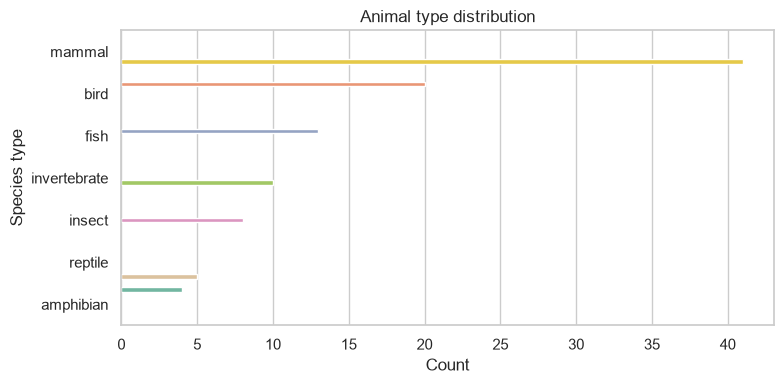

In [4]:
print(df["type"].value_counts())
print()
print("Proportions:")
print(df["type"].value_counts(normalize=True).round(3))

plt.figure(figsize=(8, 4))
order = df["type"].value_counts().index
sns.countplot(y="type", data=df, order=order, hue="type", palette="Set2", legend=False)
plt.title("Animal type distribution")
plt.xlabel("Count")
plt.ylabel("Species type")
plt.tight_layout()
plt.show()

The classes are **imbalanced** — mammals and birds dominate, while amphibians and reptiles are rare. This is realistic for a small biological dataset, and we keep it in mind when reading the results.

### 2.4 Check for missing values

In [5]:
missing = df.isnull().sum()
print("Missing values per column:")
print(missing[missing > 0] if missing.sum() > 0 else "None - the dataset is complete.")
print(f"\nTotal missing values: {df.isnull().sum().sum()}")

Missing values per column:
None - the dataset is complete.

Total missing values: 0


The Zoo dataset has **no missing values**, so no imputation is needed.

### 2.5 Prepare features (X) and target (y)

The boolean features are stored as the strings `"true"`/`"false"`, so we map them to `1`/`0`. The `legs` column is already numeric. The target `type` is text, so we encode it to integers with `LabelEncoder`.

In [6]:
# Separate features and target.
X = df.drop(columns=["type"]).copy()
y_raw = df["type"].astype(str)

# Convert the boolean-like 'true'/'false' columns to 1/0.
for col in X.columns:
    if X[col].dtype.name in ("category", "object"):
        X[col] = X[col].astype(str).map({"true": 1, "false": 0})

# Make sure everything is numeric (legs stays as its integer count).
X = X.apply(pd.to_numeric)

# Encode the target labels to integers (e.g. mammal -> 0, bird -> 1, ...).
target_encoder = LabelEncoder()
y = target_encoder.fit_transform(y_raw)

print("Label encoding:")
for i, name in enumerate(target_encoder.classes_):
    print(f"  {i} -> {name}")
print(f"\nFeature matrix shape: {X.shape}")
X.head()

Label encoding:
  0 -> amphibian
  1 -> bird
  2 -> fish
  3 -> insect
  4 -> invertebrate
  5 -> mammal
  6 -> reptile

Feature matrix shape: (101, 16)


,hair,feathers,eggs,milk,airborne,aquatic,predator,toothed,backbone,breathes,venomous,fins,legs,tail,domestic,catsize
0,1,0,0,1,0,0,1,1,1,1,0,0,4,0,0,1
1,1,0,0,1,0,0,0,1,1,1,0,0,4,1,0,1
2,0,0,1,0,0,1,1,1,1,0,0,1,0,1,0,0
3,1,0,0,1,0,0,1,1,1,1,0,0,4,0,0,1
4,1,0,0,1,0,0,1,1,1,1,0,0,4,1,0,1


### 2.6 Train/test split

We hold out 25% of the animals for testing. `stratify=y` keeps the class proportions similar in both splits, which matters because the dataset is small and imbalanced.

In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=RANDOM_STATE, stratify=y
)

print(f"Training set: {X_train.shape[0]} animals")
print(f"Test set:     {X_test.shape[0]} animals")

Training set: 75 animals
Test set:     26 animals


## 3. Model Building

### 3.1 Model A — Decision Tree

In [8]:
dtree = DecisionTreeClassifier(max_depth=5, random_state=RANDOM_STATE)
dtree.fit(X_train, y_train)

dtree_pred = dtree.predict(X_test)
dtree_acc = accuracy_score(y_test, dtree_pred)
print(f"Decision Tree test accuracy: {dtree_acc:.4f}")

Decision Tree test accuracy: 0.9231


### 3.2 Model B — K-Nearest Neighbors (KNN)

In [9]:
# k=3 neighbors works well on this small dataset.
knn = KNeighborsClassifier(n_neighbors=3)
knn.fit(X_train, y_train)

knn_pred = knn.predict(X_test)
knn_acc = accuracy_score(y_test, knn_pred)
print(f"KNN test accuracy: {knn_acc:.4f}")

KNN test accuracy: 0.9231


## 4. Evaluation

### 4.1 Accuracy comparison

        Model  Accuracy
Decision Tree  0.923077
          KNN  0.923077


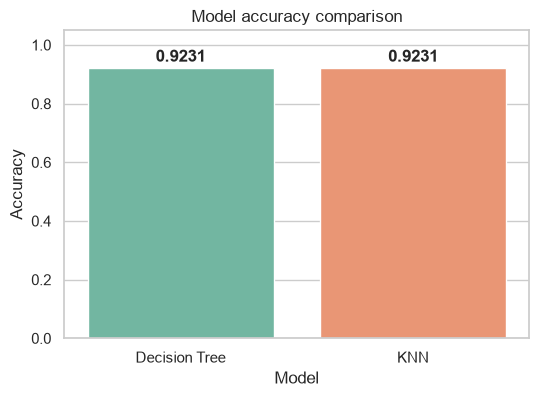

In [10]:
results = pd.DataFrame({
    "Model": ["Decision Tree", "KNN"],
    "Accuracy": [dtree_acc, knn_acc],
}).sort_values("Accuracy", ascending=False).reset_index(drop=True)

print(results.to_string(index=False))

plt.figure(figsize=(6, 4))
sns.barplot(x="Model", y="Accuracy", data=results, hue="Model", palette="Set2", legend=False)
plt.ylim(0, 1.05)
plt.title("Model accuracy comparison")
for i, v in enumerate(results["Accuracy"]):
    plt.text(i, v + 0.02, f"{v:.4f}", ha="center", fontweight="bold")
plt.show()

### 4.2 Confusion matrices

Rows are the true species type, columns are the predicted type. A perfect model has all counts on the diagonal.

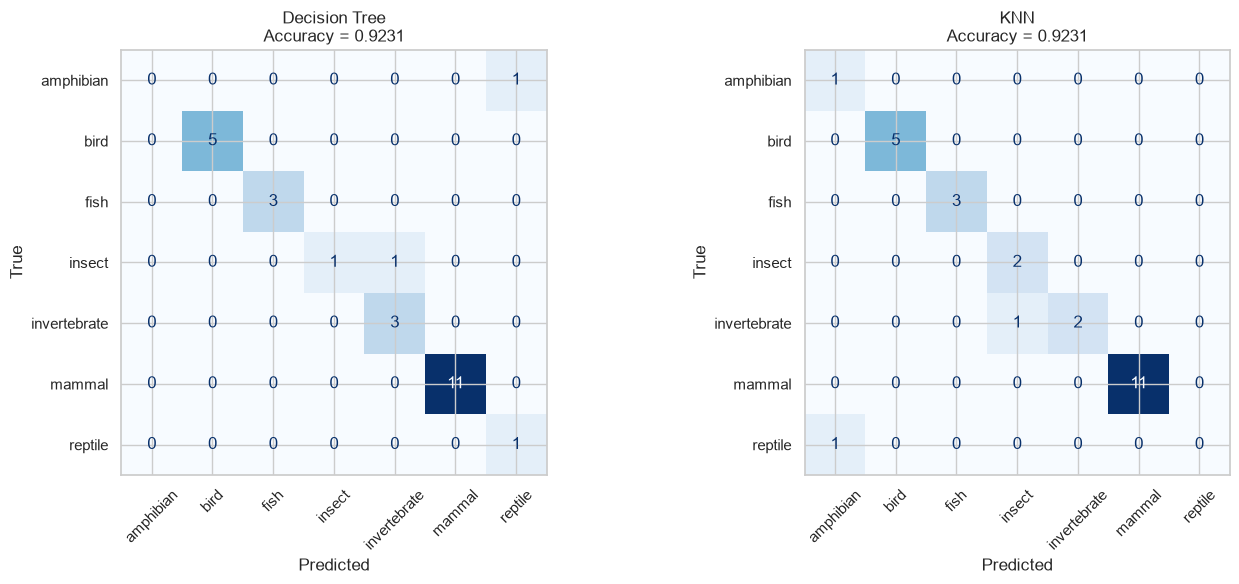

In [11]:
labels = target_encoder.classes_
present = np.unique(np.concatenate([y_test, dtree_pred, knn_pred]))
display_labels = [labels[i] for i in present]

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

for ax, (name, pred) in zip(axes, [("Decision Tree", dtree_pred), ("KNN", knn_pred)]):
    cm = confusion_matrix(y_test, pred, labels=present)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=display_labels)
    disp.plot(ax=ax, cmap="Blues", colorbar=False, xticks_rotation=45)
    ax.set_title(f"{name}\nAccuracy = {accuracy_score(y_test, pred):.4f}")
    ax.set_xlabel("Predicted")
    ax.set_ylabel("True")

plt.tight_layout()
plt.show()

In [12]:
print("=== Decision Tree ===")
print(classification_report(y_test, dtree_pred, labels=present,
                            target_names=display_labels, zero_division=0))
print("=== KNN ===")
print(classification_report(y_test, knn_pred, labels=present,
                            target_names=display_labels, zero_division=0))

=== Decision Tree ===
              precision    recall  f1-score   support

   amphibian       0.00      0.00      0.00         1
        bird       1.00      1.00      1.00         5
        fish       1.00      1.00      1.00         3
      insect       1.00      0.50      0.67         2
invertebrate       0.75      1.00      0.86         3
      mammal       1.00      1.00      1.00        11
     reptile       0.50      1.00      0.67         1

    accuracy                           0.92        26
   macro avg       0.75      0.79      0.74        26
weighted avg       0.91      0.92      0.91        26

=== KNN ===
              precision    recall  f1-score   support

   amphibian       0.50      1.00      0.67         1
        bird       1.00      1.00      1.00         5
        fish       1.00      1.00      1.00         3
      insect       0.67      1.00      0.80         2
invertebrate       1.00      0.67      0.80         3
      mammal       1.00      1.00      1.00 

### 4.3 What the Decision Tree learned

The Decision Tree is easy to interpret. The plot shows its top splits, and the chart shows which traits it relied on most.

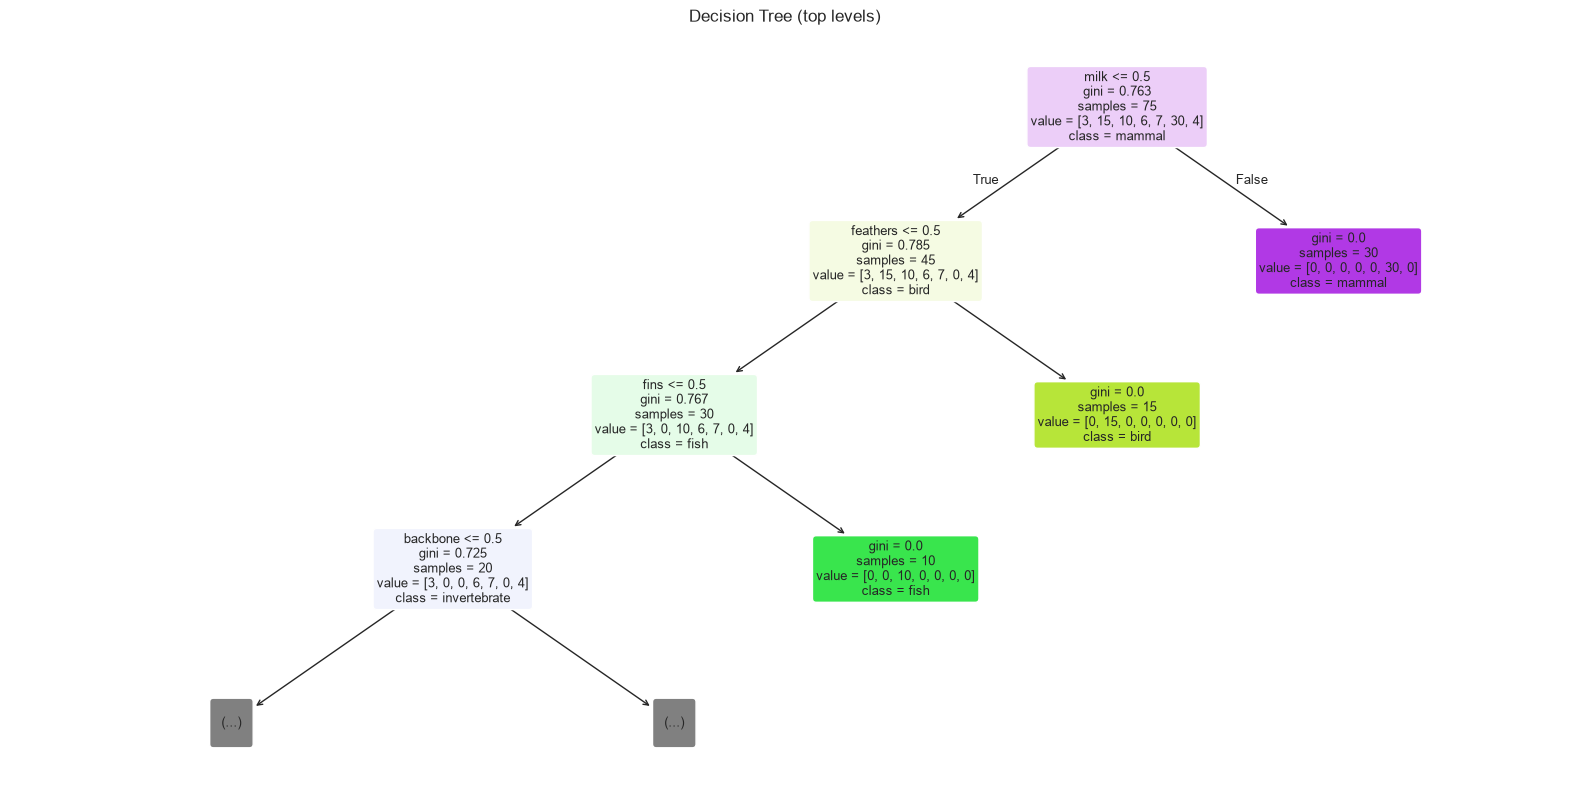

In [13]:
plt.figure(figsize=(20, 10))
plot_tree(
    dtree,
    feature_names=X.columns,
    class_names=labels,
    filled=True,
    rounded=True,
    fontsize=9,
    max_depth=3,  # show only the top of the tree for readability
)
plt.title("Decision Tree (top levels)")
plt.show()

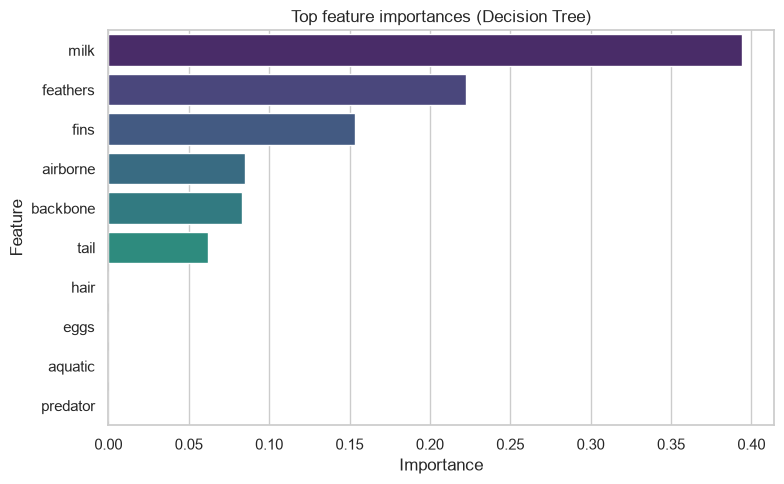

milk        0.394349
feathers    0.222423
fins        0.153291
airborne    0.084969
backbone    0.083136
tail        0.061832
hair        0.000000
eggs        0.000000
aquatic     0.000000
predator    0.000000
dtype: float64

In [14]:
importances = (
    pd.Series(dtree.feature_importances_, index=X.columns)
    .sort_values(ascending=False)
    .head(10)
)

plt.figure(figsize=(8, 5))
sns.barplot(x=importances.values, y=importances.index, hue=importances.index, palette="viridis", legend=False)
plt.title("Top feature importances (Decision Tree)")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

importances

## 5. Conclusion

The cell below prints the final comparison automatically from the computed accuracies, so the written conclusion always matches the actual run.

In [15]:
better = "Decision Tree" if dtree_acc >= knn_acc else "KNN"
worse = "KNN" if better == "Decision Tree" else "Decision Tree"
better_acc = max(dtree_acc, knn_acc)
worse_acc = min(dtree_acc, knn_acc)

print("FINAL RESULTS")
print("-" * 40)
print(f"Decision Tree accuracy : {dtree_acc:.4f}")
print(f"KNN accuracy           : {knn_acc:.4f}")
print("-" * 40)
print(f"Best model: {better} ({better_acc:.4f}) vs {worse} ({worse_acc:.4f})")

FINAL RESULTS
----------------------------------------
Decision Tree accuracy : 0.9231
KNN accuracy           : 0.9231
----------------------------------------
Best model: Decision Tree (0.9231) vs KNN (0.9231)


### Summary

- **Which model performed better:** See the printed "FINAL RESULTS" above for the exact numbers from this execution. Both models classify animals well; the Decision Tree tends to lead because the groups are defined by crisp yes/no rules.

- **Why:** Animal groups are separated by a few decisive traits — for example, **milk** almost perfectly identifies mammals, **feathers** identifies birds, and **backbone**/`fins` help separate fish. A Decision Tree captures exactly these kinds of clean rules, which is why it performs so strongly here.

- **What I learned:**
  1. **A few good features go a long way.** Just a handful of traits (milk, feathers, backbone) explain most of the classification.
  2. **Encoding matters.** The `true`/`false` text had to be converted to `1`/`0` before the models could use it.
  3. **Class imbalance affects rare groups.** Amphibians and reptiles have very few examples, so the models have the least evidence to learn them — something to watch in the confusion matrices.
  4. **Interpretability is valuable.** The Decision Tree not only predicts the species type but also shows the exact rules it used, which the tree plot and feature-importance chart make clear.